# Project 12: Understanding Convolution and Pooling
**Course:** Deep Learning  

**Aim:** See how convolution filters and pooling extract features from an image, the way a CNN does.

## Task 1: Load a sample image

Image shape: (512, 512)


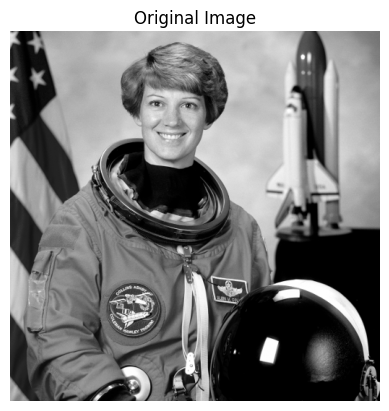

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d
from skimage import data, color

# Load a sample image and convert it to grayscale
img = color.rgb2gray(data.astronaut())

print("Image shape:", img.shape)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis('off')
plt.show()

## Task 2: Apply convolution filters and pooling

**Convolution:** a small matrix (filter/kernel) slides over the image and produces a *feature map*.  
**Pooling:** shrinks the feature map by keeping one value from each small window (max or average).

In [2]:
# Convolution filters (kernels)
blur = np.ones((3, 3)) / 9

sharpen = np.array([[ 0, -1,  0],
                    [-1,  5, -1],
                    [ 0, -1,  0]])

sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])   # detects vertical edges

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]]) # detects horizontal edges

def convolve(image, kernel):
    return convolve2d(image, kernel, mode='same', boundary='symm')

feature_maps = {
    "Blur": convolve(img, blur),
    "Sharpen": convolve(img, sharpen),
    "Vertical Edges (Sobel X)": convolve(img, sobel_x),
    "Horizontal Edges (Sobel Y)": convolve(img, sobel_y),
}

In [3]:
# Pooling operations (2x2 window, stride 2)
def max_pool(image, size=2):
    h, w = image.shape
    h, w = h - h % size, w - w % size
    x = image[:h, :w].reshape(h // size, size, w // size, size)
    return x.max(axis=(1, 3))

def avg_pool(image, size=2):
    h, w = image.shape
    h, w = h - h % size, w - w % size
    x = image[:h, :w].reshape(h // size, size, w // size, size)
    return x.mean(axis=(1, 3))

edge_map = feature_maps["Vertical Edges (Sobel X)"]
edge_max = max_pool(edge_map)
edge_avg = avg_pool(edge_map)

print("Feature map shape :", edge_map.shape)
print("After max pooling :", edge_max.shape)
print("After avg pooling :", edge_avg.shape)

Feature map shape : (512, 512)
After max pooling : (256, 256)
After avg pooling : (256, 256)


## Task 3: Visualize and compare

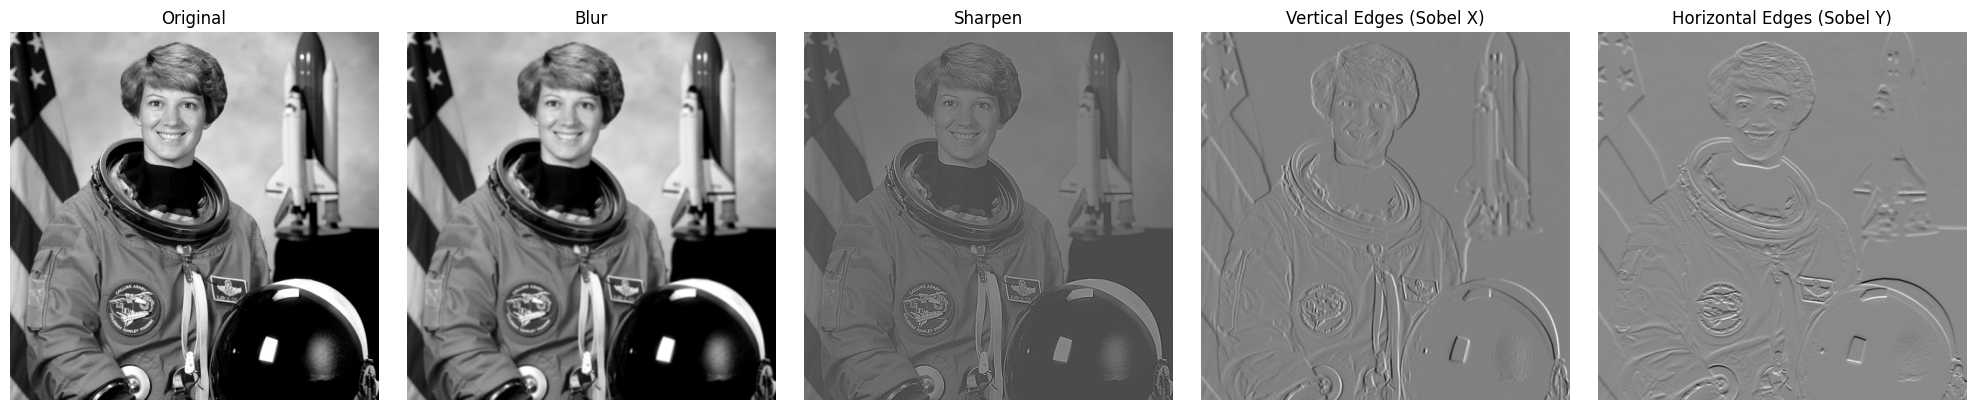

In [4]:
# Original vs. convolution feature maps
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
axes[0].imshow(img, cmap='gray')
axes[0].set_title("Original")
for ax, (name, fm) in zip(axes[1:], feature_maps.items()):
    ax.imshow(fm, cmap='gray')
    ax.set_title(name)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

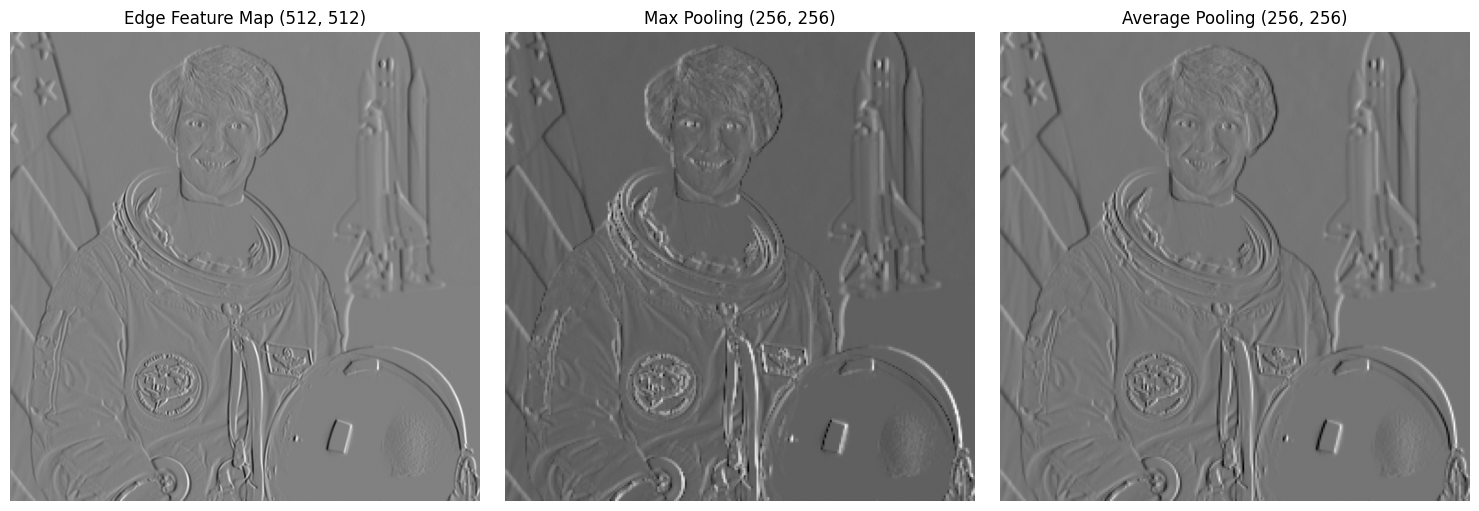

In [5]:
# Pooling comparison on the edge feature map
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(edge_map, cmap='gray'); axes[0].set_title(f"Edge Feature Map {edge_map.shape}")
axes[1].imshow(edge_max, cmap='gray'); axes[1].set_title(f"Max Pooling {edge_max.shape}")
axes[2].imshow(edge_avg, cmap='gray'); axes[2].set_title(f"Average Pooling {edge_avg.shape}")
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Observations / Conclusion

- **Blur** smooths the image and removes small details and noise.
- **Sharpen** makes edges and details stand out more.
- **Sobel X / Sobel Y** detect vertical and horizontal edges, which are basic features a CNN learns in its first layers.
- **Max pooling** keeps the strongest value in each window, so important features (like edges) stay bright.
- **Average pooling** takes the mean of each window, so the result is smoother and less sharp.
- Pooling reduces the image size to half (512x512 to 256x256), which lowers computation and makes the network less sensitive to small shifts.

Therefore, CNNs use convolution to extract features and pooling to shrink and summarize them.